In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [64]:
FILENAME = 'BankNoteAuthentication.csv'
random_state = 42
test_size = 0.3
df = pd.read_csv(FILENAME)

In [65]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB


In [66]:
df.isna().sum()

variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

In [67]:
features = ['variance', 'skewness', 'curtosis', 'entropy']
target = ['class']

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=test_size,
    random_state=random_state
)

In [86]:
X_train.describe()

,variance,skewness,curtosis,entropy
count,960.000000,960.000000,960.000000,960.000000
mean,0.409875,1.850630,1.446693,-1.199246
std,2.858811,5.923107,4.351654,2.085500
min,-7.042100,-13.773100,-5.261300,-8.548200
25%,-1.805350,-1.875850,-1.457600,-2.382450
50%,0.398130,2.405550,0.596925,-0.615095
75%,2.928000,6.748925,3.146250,0.399980
max,6.824800,12.951600,17.927400,2.162500


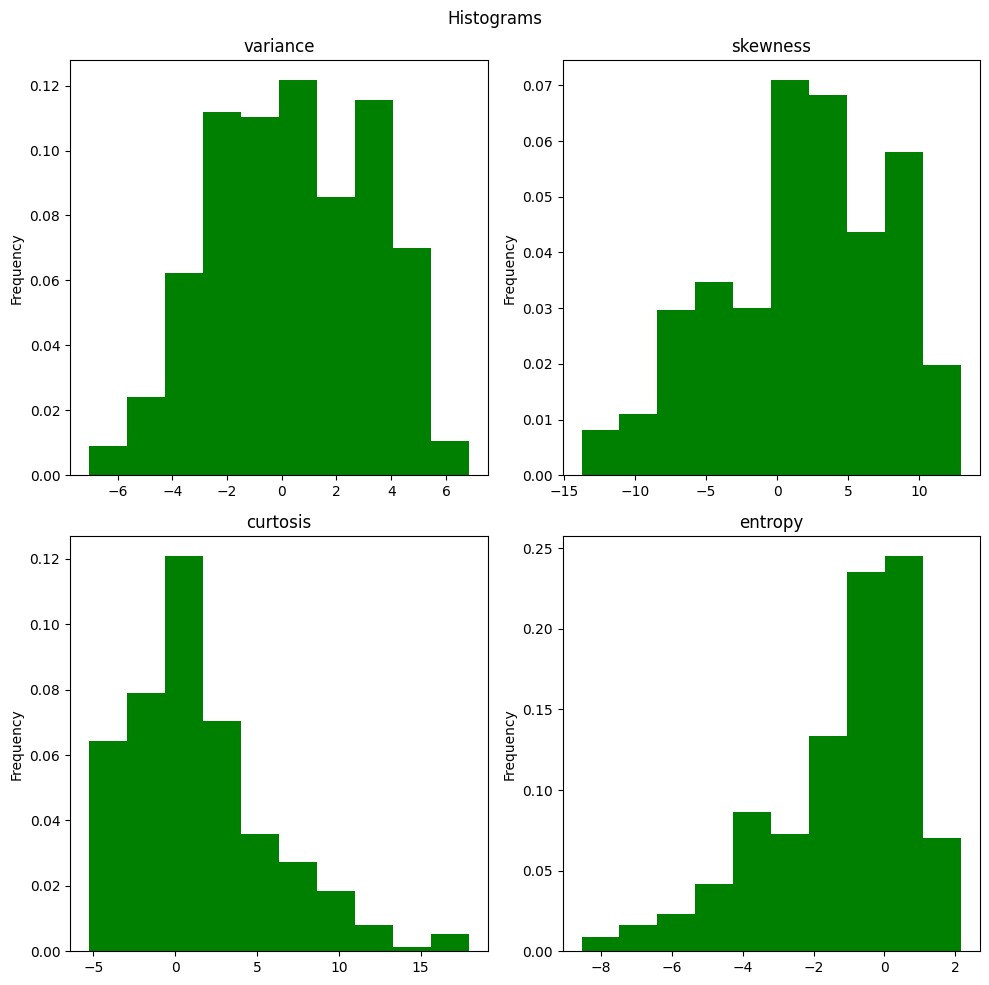

In [106]:
fig, ax = plt.subplots(2, 2, figsize=(10,10))

for i, feature in enumerate(features):
    X_train[feature].plot(
        kind='hist',
        title=feature,
        density=True,
        color='green',
        ax=ax[i//2, i%2]
    )

plt.suptitle('Histograms')
plt.tight_layout()
plt.show()

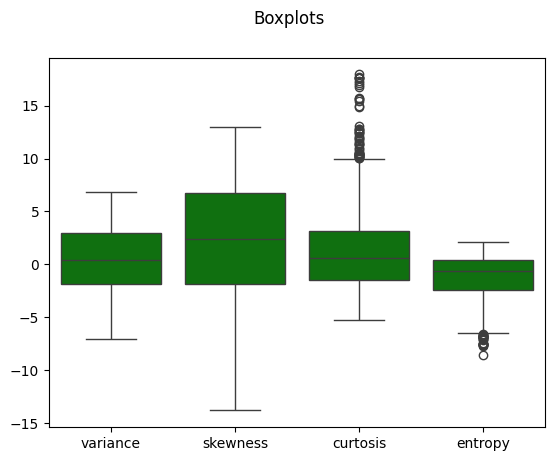

In [112]:
sns.boxplot(X_train, color='green')
plt.suptitle('Boxplots')
plt.show()

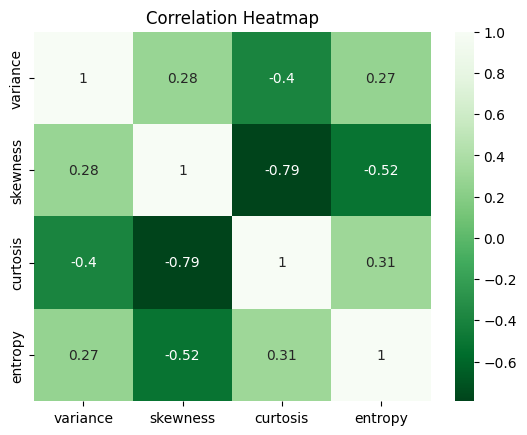

In [ ]:
corr = X_train.corr()
ax = sns.heatmap(
    data=corr,
    annot=True,
    cmap='Greens_r'
)
ax.set_title('Correlation Heatmap')
plt.show()

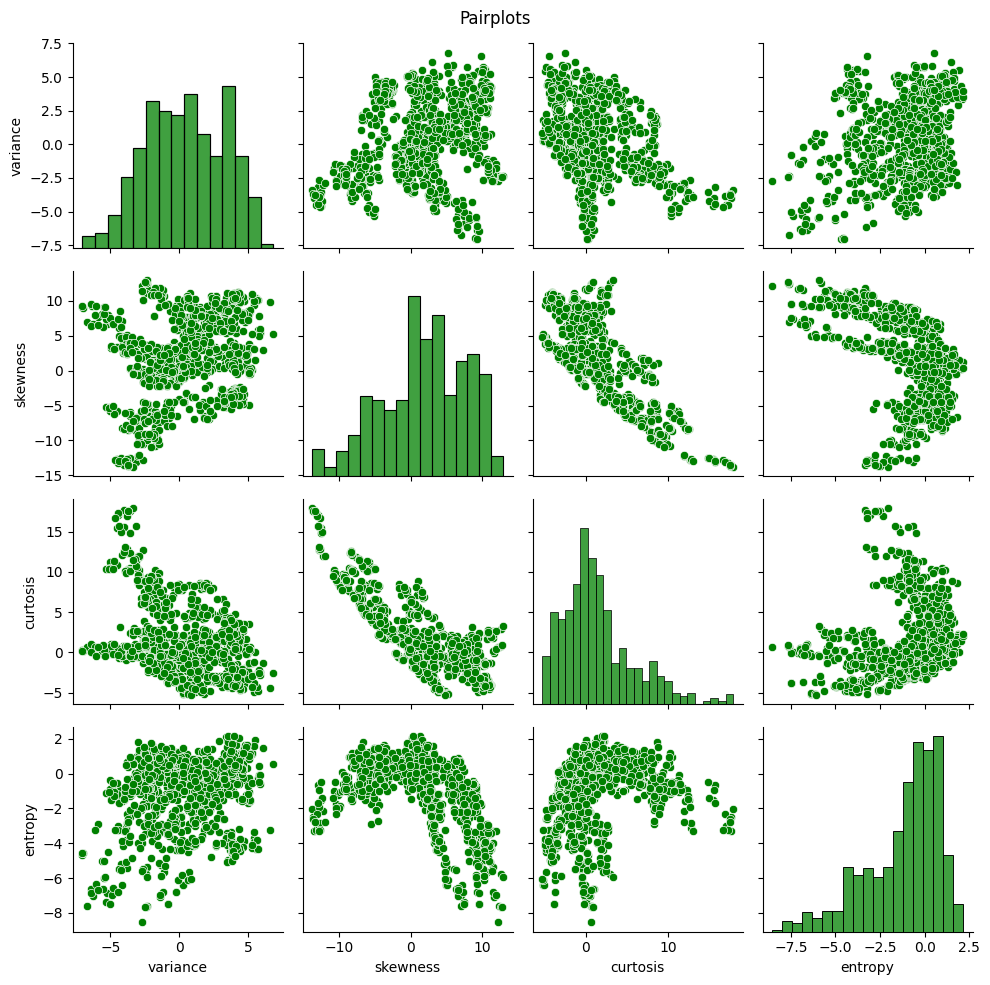

In [105]:
sns.pairplot(
    X_train,
    plot_kws={'color': 'green'},
    diag_kws={'color': 'green'}
)
plt.suptitle('Pairplots')
plt.tight_layout()
plt.show()